# Fake News Detection on the LIAR Dataset — Algorithm 3 (L3): Random Forest

This notebook implements **L3 — Random Forest**, using the same TF-IDF + default-hyperparameter
pipeline as A1-A4, but applied to the **LIAR benchmark dataset** instead of
`fake_or_real_news.csv`, so results are internally comparable across L1-L4 while remaining a fair,
separate benchmark from the A1-A4 results.

**Dataset:** LIAR (Wang, ACL 2017) — 12,836 short political statements fact-checked by
PolitiFact, pre-split into `train.tsv` (10,269), `valid.tsv` (1,284) and `test.tsv` (1,283).
The original 6-point truth scale is mapped to 4 classes: **Real, Misleading, Partially False,
Fake** (see `liar_dataset_exploration.ipynb` for the full mapping rationale).

This is a **different dataset** from the one used in A1-A4 — different source, size, text type
(short statements vs. full articles) and label scheme (4-class vs. binary) — so its results
should be reported and compared separately from A1-A4, not merged with them.


In [1]:
# Step 1: Imports
import re
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = os.path.abspath(".")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

sns.set_style("whitegrid")
pd.set_option("display.max_colwidth", 100)
RANDOM_STATE = 42
CLASS_ORDER = ["Real", "Misleading", "Partially False", "Fake"]


In [2]:
# Step 2: Load the official LIAR train / valid / test splits
from src.data_loader import load_raw_split, LIAR_COLUMNS, LIAR_TO_4CLASS

train_df = load_raw_split("data/raw/train.tsv")
valid_df = load_raw_split("data/raw/valid.tsv")
test_df  = load_raw_split("data/raw/test.tsv")

print("train.tsv:", train_df.shape)
print("valid.tsv:", valid_df.shape)
print("test.tsv :", test_df.shape)
train_df.head()


train.tsv: (10269, 14)
valid.tsv: (1284, 14)
test.tsv : (1283, 14)


,id,raw_label,statement,subjects,speaker,speaker_job_title,state_info,party_affiliation,barely_true_counts,false_counts,half_true_counts,mostly_true_counts,pants_on_fire_counts,context
0,2635.json,false,Says the Annies List political group supports third-trimester abortions on demand.,abortion,dwayne-bohac,State representative,Texas,republican,0,1,0,0,0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started when natural gas took off that started to begin i...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0,0,1,1,0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt ...",foreign-policy,barack-obama,President,Illinois,democrat,70,71,160,163,9,Denver
3,1123.json,false,Health care reform legislation is likely to mandate free sex change surgeries.,health-care,blog-posting,NaN,NaN,none,7,19,3,5,44,a news release
4,9028.json,half-true,The economic turnaround started at the end of my term.,"economy,jobs",charlie-crist,NaN,Florida,democrat,15,9,20,19,2,an interview on CNN


In [3]:
# Step 3: Inspect missing values and the original 6-class label distribution (train split)
print(train_df.info())
print("\nMissing values per column (train):\n", train_df.isnull().sum())
print("\nOriginal 6-class label distribution (train):\n", train_df['raw_label'].value_counts())


<class 'pandas.DataFrame'>
RangeIndex: 10269 entries, 0 to 10268
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   id                    10269 non-null  str  
 1   raw_label             10269 non-null  str  
 2   statement             10269 non-null  str  
 3   subjects              10269 non-null  str  
 4   speaker               10269 non-null  str  
 5   speaker_job_title     7367 non-null   str  
 6   state_info            8058 non-null   str  
 7   party_affiliation     10269 non-null  str  
 8   barely_true_counts    10269 non-null  int64
 9   false_counts          10269 non-null  int64
 10  half_true_counts      10269 non-null  int64
 11  mostly_true_counts    10269 non-null  int64
 12  pants_on_fire_counts  10269 non-null  int64
 13  context               10169 non-null  str  
dtypes: int64(5), str(9)
memory usage: 1.1 MB
None

Missing values per column (train):
 id                         0
r

In [4]:
# Step 4: Map PolitiFact's 6-point truth scale to the project's 4 reliability classes
# (true -> Real, mostly-true -> Misleading, half-true/barely-true -> Partially False,
# false/pants-fire -> Fake) and drop any missing/empty statements or unmapped labels.
for df in (train_df, valid_df, test_df):
    df['label'] = df['raw_label'].map(LIAR_TO_4CLASS)
    df.dropna(subset=['statement', 'label'], inplace=True)
    df.drop(df[df['statement'].astype(str).str.strip() == ''].index, inplace=True)
    df.reset_index(drop=True, inplace=True)

print("Shapes after mapping/cleaning -> train:", train_df.shape,
      " valid:", valid_df.shape, " test:", test_df.shape)
print("\nMapped 4-class distribution (train):\n",
      train_df['label'].value_counts().reindex(CLASS_ORDER))


Shapes after mapping/cleaning -> train: (10269, 15)  valid: (1284, 15)  test: (1283, 15)

Mapped 4-class distribution (train):
 label
Real               1683
Misleading         1966
Partially False    3780
Fake               2840
Name: count, dtype: int64


In [5]:
# Step 5: Preprocess the statement text (lowercase, strip URLs/punctuation/digits/whitespace).
# Stopword removal is handled by TfidfVectorizer, same as A1-A4.
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

for df in (train_df, valid_df, test_df):
    df['clean_statement'] = df['statement'].apply(preprocess_text)

train_df[['statement', 'clean_statement']].head(3)


,statement,clean_statement
0,Says the Annies List political group supports third-trimester abortions on demand.,says the annies list political group supports third trimester abortions on demand
1,When did the decline of coal start? It started when natural gas took off that started to begin i...,when did the decline of coal start it started when natural gas took off that started to begin in...
2,"Hillary Clinton agrees with John McCain ""by voting to give George Bush the benefit of the doubt ...",hillary clinton agrees with john mccain by voting to give george bush the benefit of the doubt o...


In [6]:
# Step 6: TF-IDF vectorization, same parameters as A1-A4 (max 5,000 unigram features,
# English stopwords removed). Fit on train only; transform valid/test with that vocabulary.
tfidf = TfidfVectorizer(stop_words='english', max_features=5000, ngram_range=(1, 1))

X_train = tfidf.fit_transform(train_df['clean_statement'])
X_valid = tfidf.transform(valid_df['clean_statement'])
X_test  = tfidf.transform(test_df['clean_statement'])

y_train = train_df['label']
y_valid = valid_df['label']
y_test  = test_df['label']

print("TF-IDF shapes -> train:", X_train.shape, " valid:", X_valid.shape, " test:", X_test.shape)


TF-IDF shapes -> train: (10269, 5000)  valid: (1284, 5000)  test: (1283, 5000)


## Note on the train/test split

Unlike `fake_or_real_news.csv` (used in A1-A4), LIAR ships as **fixed** `train` / `valid` / `test`
files rather than one pool we split ourselves. To stay comparable with the published LIAR
benchmark, we train on `train.tsv`, keep `valid.tsv` aside for tuning (not used here since all
four models use default hyperparameters, same as A1-A4), and report every metric on the untouched
`test.tsv`. No `train_test_split` / `random_state` step is needed for this dataset.


In [7]:
# Step 7: Initialize Random Forest (L3)
rf_model = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_model

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [8]:
# Step 8: Train the model
rf_model.fit(X_train, y_train)
print("L3 (Random Forest) training complete.")


L3 (Random Forest) training complete.


In [9]:
# Step 9: Predict on the held-out test split
y_pred_rf = rf_model.predict(X_test)
y_pred_rf[:10]


array(['Partially False', 'Fake', 'Partially False', 'Partially False',
       'Fake', 'Partially False', 'Fake', 'Partially False',
       'Partially False', 'Misleading'], dtype=object)

In [10]:
# Step 10: Accuracy, precision, recall and F1 (macro-averaged across the 4 classes,
# since LIAR is multi-class, unlike A1-A4's binary REAL/FAKE)
acc_rf  = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, average='macro', zero_division=0)
rec_rf  = recall_score(y_test, y_pred_rf, average='macro', zero_division=0)
f1_rf   = f1_score(y_test, y_pred_rf, average='macro', zero_division=0)

print("L3 - Random Forest Results (LIAR test split)")
print(f"Accuracy          : {acc_rf:.4f}")
print(f"Precision (macro) : {prec_rf:.4f}")
print(f"Recall (macro)    : {rec_rf:.4f}")
print(f"F1-score (macro)  : {f1_rf:.4f}")
print("\nFull classification report:\n")
print(classification_report(y_test, y_pred_rf))


L3 - Random Forest Results (LIAR test split)
Accuracy          : 0.3726
Precision (macro) : 0.3038
Recall (macro)    : 0.2890
F1-score (macro)  : 0.2646

Full classification report:

                 precision    recall  f1-score   support

           Fake       0.36      0.31      0.33       342
     Misleading       0.22      0.07      0.10       249
Partially False       0.40      0.71      0.51       481
           Real       0.24      0.07      0.11       211

       accuracy                           0.37      1283
      macro avg       0.30      0.29      0.26      1283
   weighted avg       0.33      0.37      0.32      1283



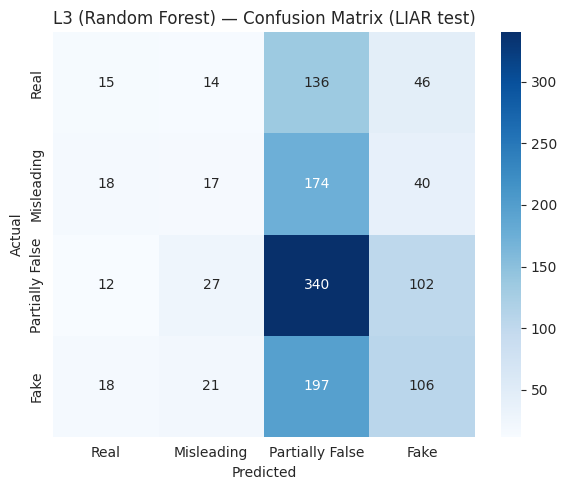

In [11]:
# Step 11: Confusion matrix (4x4, since LIAR has 4 classes vs A1-A4's 2)
cm_rf = confusion_matrix(y_test, y_pred_rf, labels=CLASS_ORDER)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER)
plt.title("L3 (Random Forest) — Confusion Matrix (LIAR test)")
plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout()
plt.show()


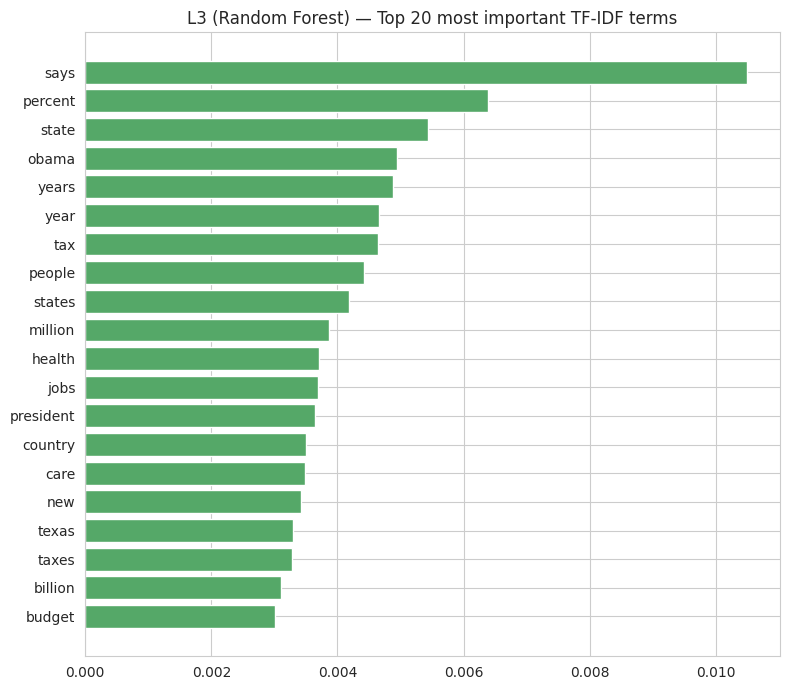

In [12]:
# Step 12: Inspect the most important TF-IDF terms overall (Random Forest gives one
# global importance score per feature rather than one per class)
feature_names = np.array(tfidf.get_feature_names_out())
importances = rf_model.feature_importances_
top_n = 20
top_idx = np.argsort(importances)[-top_n:]

plt.figure(figsize=(8, 7))
plt.barh(feature_names[top_idx], importances[top_idx], color='#55A868')
plt.title("L3 (Random Forest) — Top 20 most important TF-IDF terms")
plt.tight_layout()
plt.show()


In [13]:
# Step 13: Train the other three algorithms for comparison (same TF-IDF features, same splits)
lr_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

svm_model = LinearSVC(random_state=RANDOM_STATE)
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)

nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

print("L1 (Logistic Regression), L2 (SVM), L4 (Naive Bayes) trained.")

L1 (Logistic Regression), L2 (SVM), L4 (Naive Bayes) trained.


In [14]:
# Step 14: Compare all four algorithms in a results DataFrame (macro-averaged metrics)
def get_metrics(name, y_true, y_pred):
    return {
        'Algorithm': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision (macro)': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'Recall (macro)': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'F1-score (macro)': f1_score(y_true, y_pred, average='macro', zero_division=0),
    }

results = pd.DataFrame([
    get_metrics('L1 - Logistic Regression', y_test, y_pred_lr),
    get_metrics('L2 - SVM', y_test, y_pred_svm),
    get_metrics('L3 - Random Forest', y_test, y_pred_rf),
    get_metrics('L4 - Naive Bayes', y_test, y_pred_nb),
])
results = results.set_index('Algorithm').round(4)
results


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Algorithm,,,,
L1 - Logistic Regression,0.3819,0.3371,0.3155,0.3065
L2 - SVM,0.3546,0.3110,0.3097,0.3076
L3 - Random Forest,0.3726,0.3038,0.2890,0.2646
L4 - Naive Bayes,0.3843,0.3827,0.2812,0.2322


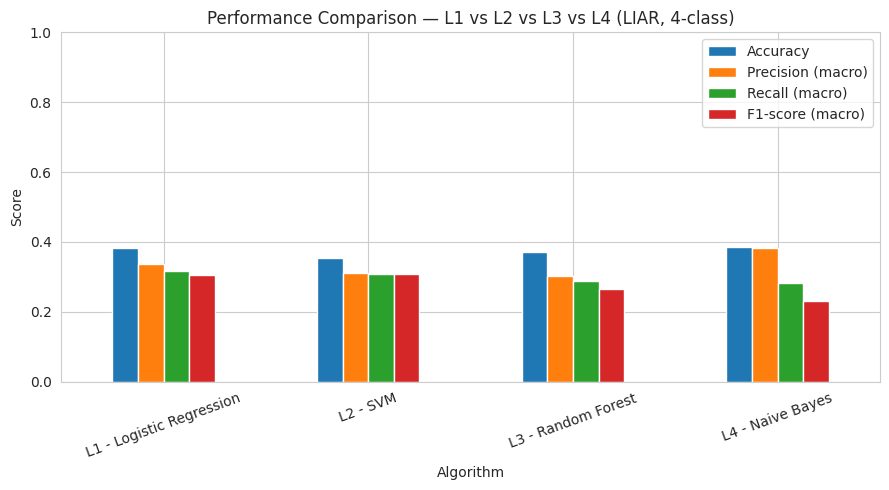

In [15]:
# Visualize the comparison
results.plot(kind='bar', figsize=(9, 5))
plt.title("Performance Comparison — L1 vs L2 vs L3 vs L4 (LIAR, 4-class)")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [16]:
# Step 15: Select the best-performing model
best_model_name = results['F1-score (macro)'].idxmax()
print(f"Best-performing model on LIAR (by macro F1-score): {best_model_name}")
results.loc[[best_model_name]]


Best-performing model on LIAR (by macro F1-score): L2 - SVM


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Algorithm,,,,
L2 - SVM,0.3546,0.311,0.3097,0.3076


## Execution Example

Testing the trained L3 (Random Forest) pipeline on an illustrative political statement,
for a direct comparison with A1-A4's new-article example.


In [17]:
# Step 16: Test on a new, unseen statement
new_statement = (
    "Says the president cut funding for veterans' hospitals by half during his first year in office."
)

clean_new = preprocess_text(new_statement)
new_vec = tfidf.transform([clean_new])

pred_class = rf_model.predict(new_vec)[0]
pred_proba = rf_model.predict_proba(new_vec)[0]
class_labels = rf_model.classes_
confidence = pred_proba[list(class_labels).index(pred_class)]

print("Input statement:", new_statement)
print(f"\nPredicted class : {pred_class}")
print(f"Confidence      : {confidence*100:.1f}%")
print("\nFull class probabilities:")
for c, p in sorted(zip(class_labels, pred_proba), key=lambda x: -x[1]):
    print(f"  {c:18s}: {p*100:5.1f}%")


Input statement: Says the president cut funding for veterans' hospitals by half during his first year in office.

Predicted class : Partially False
Confidence      : 47.0%

Full class probabilities:
  Partially False   :  47.0%
  Misleading        :  27.0%
  Real              :  14.0%
  Fake              :  12.0%


## Conclusion (L3)

The Random Forest classifier (L3) was trained on the LIAR benchmark's official `train.tsv` split
(TF-IDF, max 5,000 unigram terms, `statement` text only) and evaluated on the untouched `test.tsv`
split, using the project's 4-class mapping (Real / Misleading / Partially False / Fake). Its
accuracy, macro-precision/recall/F1, confusion matrix and top feature importances were computed above, and it was
benchmarked against L1 (Logistic Regression), L2 (SVM) and L4 (Naive Bayes).

LIAR statements are short (median ~17 words) and stripped of surrounding context, so absolute
accuracy here is expected to be well below A1-A4's results on `fake_or_real_news.csv` (full
articles, binary labels) — this is a known, published characteristic of the LIAR benchmark
(the original paper reports similar accuracy ranges), not a defect in this pipeline.
